# 02. Дослідження навчальної вибірки

Тестова частина відокремлюється до цього EDA. Усі наведені нижче таблиці та графіки використовують лише навчальні дані. Моделі не навчаються, а ознаки поки не відбираються остаточно. Початковий ноутбук уже показував розподіли на всьому наборі, тому цей holdout не є повністю сліпим.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_split import load_dataset, split_dataset

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
data_path = project_root / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
dataset = load_dataset(data_path)
train, test = split_dataset(dataset)
print(f"Навчальна вибірка: {len(train)}, відкладена тестова вибірка: {len(test)}")
del dataset, test

Навчальна вибірка: 5634, відкладена тестова вибірка: 1409


## Структура та якість

Порожні рядки `TotalCharges` діагностуються окремо від пропусків Pandas. Числове перетворення є тимчасовим і не змінює даних на диску.

In [2]:
train.info()
display(pd.DataFrame({"тип": train.dtypes.astype(str), "пропуски": train.isna().sum(), "унікальних": train.nunique()}))
print(f"Повні дублікати: {train.duplicated().sum()}; дублікати ID: {train['customerID'].duplicated().sum()}")
total_text = train["TotalCharges"].astype("string").str.strip()
total_numeric = pd.to_numeric(total_text, errors="coerce")
empty_total = total_text.isna() | total_text.eq("").fillna(False)
invalid_total = total_numeric.isna() & ~empty_total
print(f"Порожні TotalCharges: {empty_total.sum()}; інші нечислові: {invalid_total.sum()}")
display(train.loc[empty_total | invalid_total, ["tenure", "TotalCharges"]].value_counts(dropna=False))

<class 'pandas.DataFrame'>
Index: 5634 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   string 
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  PaymentMeth

,тип,пропуски,унікальних
customerID,string,0,5634
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Повні дублікати: 0; дублікати ID: 0
Порожні TotalCharges: 9; інші нечислові: 0


tenure  TotalCharges
0                       9
Name: count, dtype: int64

## Баланс класів

Позитивний клас — `Yes`. Accuracy без інших метрик може маскувати помилки для меншого класу.

,кількість,частка
Churn,,
No,4139,0.734647
Yes,1495,0.265353


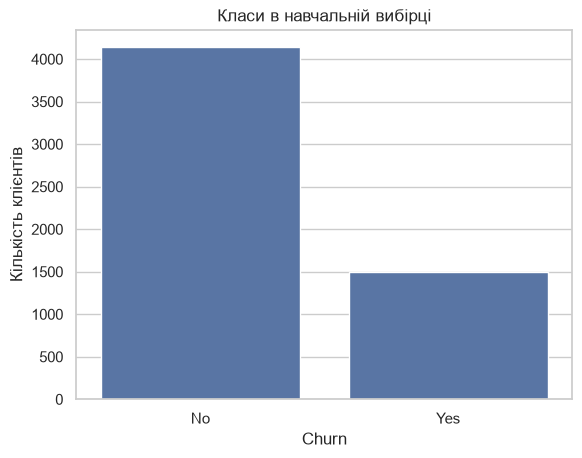

In [3]:
counts = train["Churn"].value_counts().reindex(["No", "Yes"])
display(pd.DataFrame({"кількість": counts, "частка": counts / len(train)}))
ax = sns.countplot(data=train, x="Churn", order=["No", "Yes"])
ax.set(title="Класи в навчальній вибірці", ylabel="Кількість клієнтів")
plt.show()

## Розподіли числових ознак

Медіани та графіки описують зв'язки, а не причини відтоку. `TotalCharges` перетворено лише для аналізу.

,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.555911,24.626645,0.0,9.0,29.0,56.0,72.0
MonthlyCharges,5634.0,64.77981,30.172086,18.25,35.3125,70.25,89.9875,118.65
TotalCharges,5625.0,2308.75776,2288.785138,18.85,401.5,1414.2,3848.8,8684.8


Churn,No,Yes
tenure,38.0,10.0
MonthlyCharges,64.5,79.35
TotalCharges,1718.65,703.55


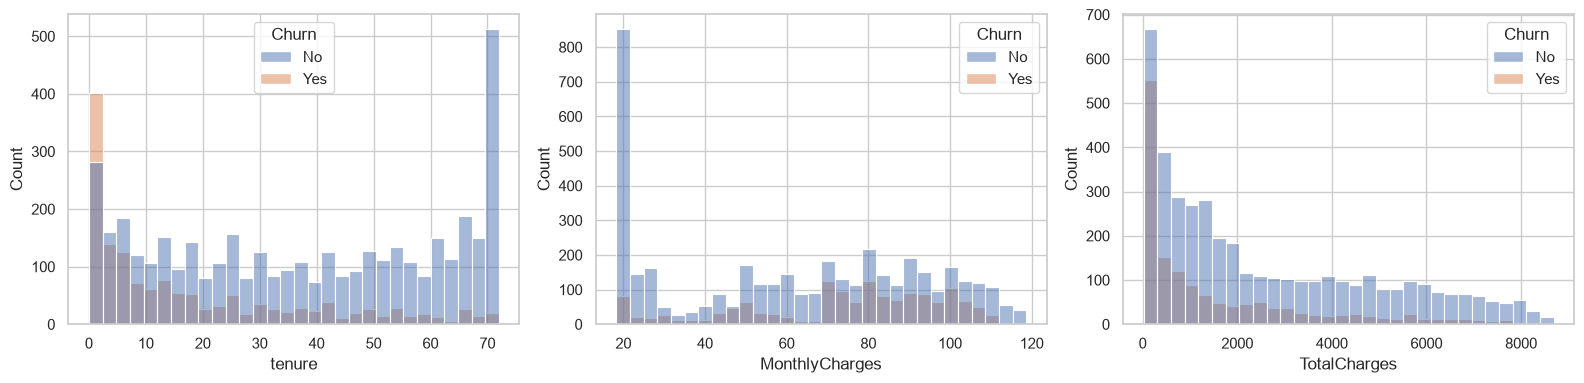

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.262718,0.828944
MonthlyCharges,0.262718,1.000000,0.658354
TotalCharges,0.828944,0.658354,1.000000


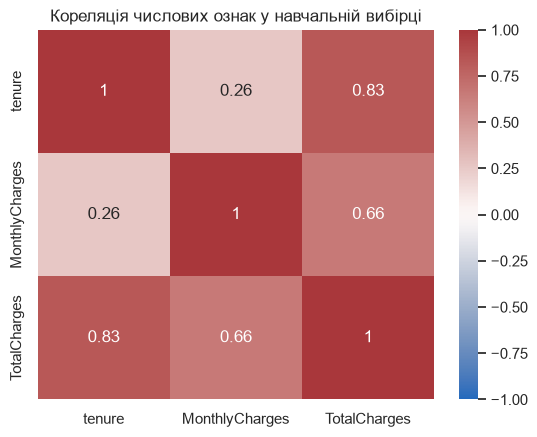

In [4]:
numeric = train[["tenure", "MonthlyCharges"]].copy()
numeric["TotalCharges"] = total_numeric
display(numeric.describe().T)
display(numeric.groupby(train["Churn"]).median().T)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_data = numeric.assign(Churn=train["Churn"])
for ax, column in zip(axes, numeric.columns):
    sns.histplot(data=plot_data, x=column, hue="Churn", bins=30, ax=ax)
fig.tight_layout()
plt.show()
display(numeric.corr())
sns.heatmap(numeric.corr(), annot=True, vmin=-1, vmax=1, cmap="vlag")
plt.title("Кореляція числових ознак у навчальній вибірці")
plt.show()

## Категоріальні ознаки та частка відтоку

Відсотки розраховуються всередині кожної категорії. У малих групах оцінки менш стабільні, тому поруч наведено розмір групи.


Contract


,кількість,частка_відтоку
Contract,,
Month-to-month,3086,0.428710
One year,1192,0.110738
Two year,1356,0.029499


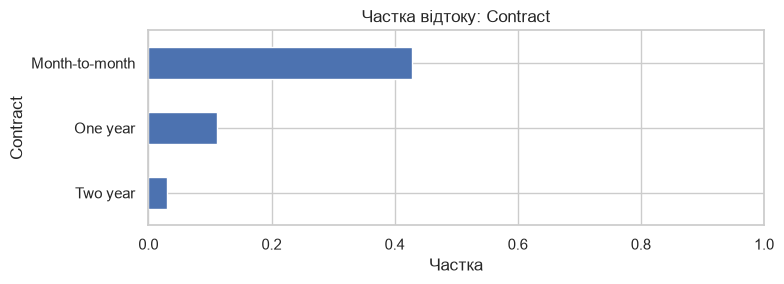


InternetService


,кількість,частка_відтоку
InternetService,,
Fiber optic,2467,0.415484
DSL,1954,0.193961
No,1213,0.075021


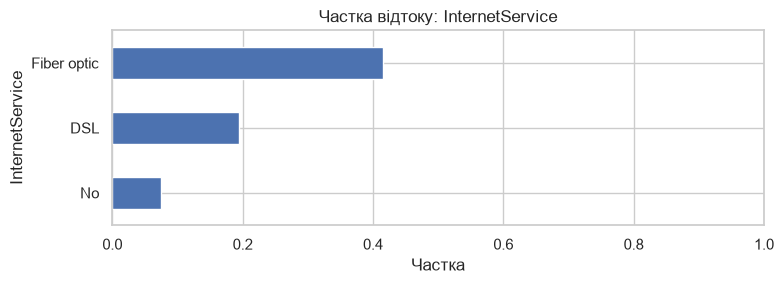


TechSupport


,кількість,частка_відтоку
TechSupport,,
No,2769,0.416757
Yes,1652,0.151332
No internet service,1213,0.075021


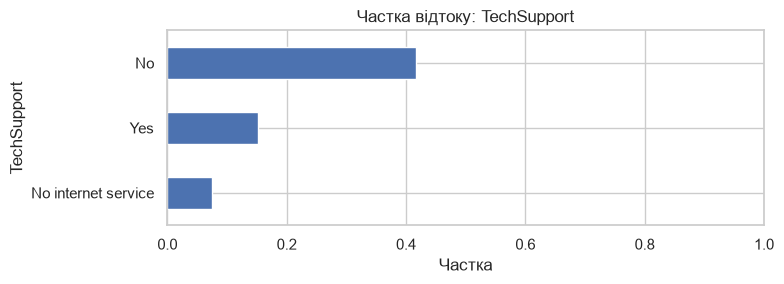


PaymentMethod


,кількість,частка_відтоку
PaymentMethod,,
Electronic check,1865,0.456300
Mailed check,1296,0.186728
Bank transfer (automatic),1228,0.170195
Credit card (automatic),1245,0.155020


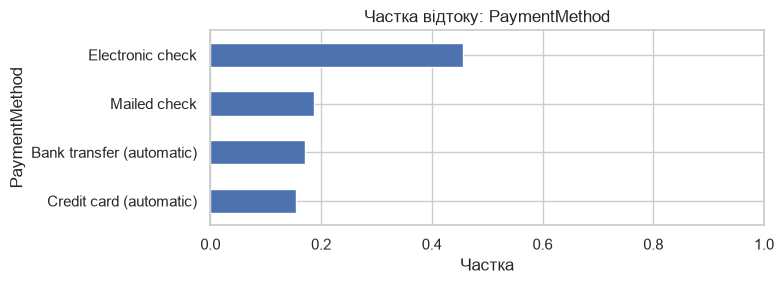

In [5]:
for column in ["Contract", "InternetService", "TechSupport", "PaymentMethod"]:
    summary = train.groupby(column, dropna=False)["Churn"].agg(
        кількість="size", частка_відтоку=lambda values: values.eq("Yes").mean()
    )
    print(f"\n{column}")
    display(summary.sort_values("частка_відтоку", ascending=False))
    ax = summary["частка_відтоку"].sort_values().plot.barh(figsize=(8, 3), xlim=(0, 1))
    ax.set(title=f"Частка відтоку: {column}", xlabel="Частка", ylabel=column)
    plt.tight_layout()
    plt.show()

## Висновки та кандидати для наступних експериментів

У навчальній частині 5 634 записи: 1 495 (26,54%) із відтоком. Виявлено 9 порожніх `TotalCharges` (усі з `tenure = 0`), інших нечислових значень і повних дублікатів немає. Медіана `tenure`: 10 місяців для `Yes` проти 38 для `No`. Частка відтоку становить 42,87% для помісячного контракту та 2,95% для дворічного. Кореляція `tenure` і `TotalCharges` — приблизно 0,83. Це описові асоціації, а не причинні висновки.

- Виключити `customerID` як ідентифікатор; решту полів перевірити на доступність на момент прогнозування.
- Розглянути `tenure`, `Contract`, `MonthlyCharges`, `TotalCharges` та характеристики послуг як кандидатів, а не як остаточний набір.
- Перевірити кореляцію платежів і тривалості та порівняти варіанти ознак усередині крос-валідації; не видаляти їх лише за кореляцією.
- `TotalCharges` потребує перетворення й обробки порожніх значень; не припускати автоматичну заміну нулем.
- Будь-яке створення, відбір, масштабування, encoding чи обробка пропусків мають навчатися тільки на навчальних фолдах pipeline.